In [6]:
from pystac_client import Client

# 1. Connect to the free Earth Search catalogue
catalog = Client.open("https://earth-search.aws.element84.com/v1")

# 2. Our area: roughly Saunders County, Nebraska  [west, south, east, north]
bbox = [-96.9, 41.0, -96.3, 41.4]

# 3. Ask the question
search = catalog.search(
    collections=["sentinel-2-l2a"],          # which satellite product
    bbox=bbox,                               # where
    datetime="2022-07-01/2022-07-31",        # when
    query={"eo:cloud_cover": {"lt": 10}},    # less than 10% cloud
)

# 4. Collect the results, least cloudy first
items = sorted(search.items(), key=lambda it: it.properties["eo:cloud_cover"])

# 5. Print one line per image
print(f"Found {len(items)} images\n")
for it in items:
    print(it.id, "| cloud %:", round(it.properties["eo:cloud_cover"], 2))

Found 13 images

S2B_14TPL_20220721_0_L2A | cloud %: 0.0
S2B_15TTF_20220721_0_L2A | cloud %: 0.0
S2B_14TQL_20220721_0_L2A | cloud %: 0.0
S2B_14TPL_20220718_0_L2A | cloud %: 0.01
S2A_14TPL_20220723_0_L2A | cloud %: 0.2
S2A_14TQL_20220713_0_L2A | cloud %: 0.44
S2A_15TTF_20220713_0_L2A | cloud %: 0.46
S2B_14TQL_20220718_0_L2A | cloud %: 0.75
S2B_15TTF_20220718_0_L2A | cloud %: 0.76
S2A_14TPL_20220713_0_L2A | cloud %: 0.94
S2A_15TTF_20220723_0_L2A | cloud %: 2.2
S2A_14TQL_20220723_0_L2A | cloud %: 2.27
S2B_15TTF_20220731_0_L2A | cloud %: 8.47


In [ ]:
import rasterio

# 1. Pick the first (least cloudy) image from our search results
item = items[0]
print("Image:", item.id)
print("Date: ", item.datetime)
print("Processing version:", item.properties["s2:processing_baseline"])

# 2. The red band of this image
red = item.assets["red"]
print("\nScale/offset label:", red.extra_fields["raster:bands"])

# 3. Open the file over the internet and read its ID card (no pixels downloaded)
with rasterio.open(red.href) as src:
    print("\nCRS (map grid):   ", src.crs)
    print("Pixel size (m):   ", src.res)
    print("Width x height:   ", src.width, "x", src.height)
    print("Bounds:           ", src.bounds)
    print("Data type:        ", src.dtypes[0])
    print("No-data value:    ", src.nodata)

Image: S2B_14TPL_20220721_0_L2A
Date:  2022-07-21 17:32:30.951000+00:00
Processing version: 04.00

Scale/offset label: [{'nodata': 0, 'data_type': 'uint16', 'bits_per_sample': 15, 'spatial_resolution': 10, 'scale': 0.0001, 'offset': -0.1}]

CRS (map grid):    EPSG:32614
Pixel size (m):    (10.0, 10.0)
Width x height:    10980 x 10980
Bounds:            BoundingBox(left=600000.0, bottom=4490220.0, right=709800.0, top=4600020.0)
Data type:         uint16
No-data value:     0.0


NDVI lowest / middle / highest: -0.29 0.78 0.94


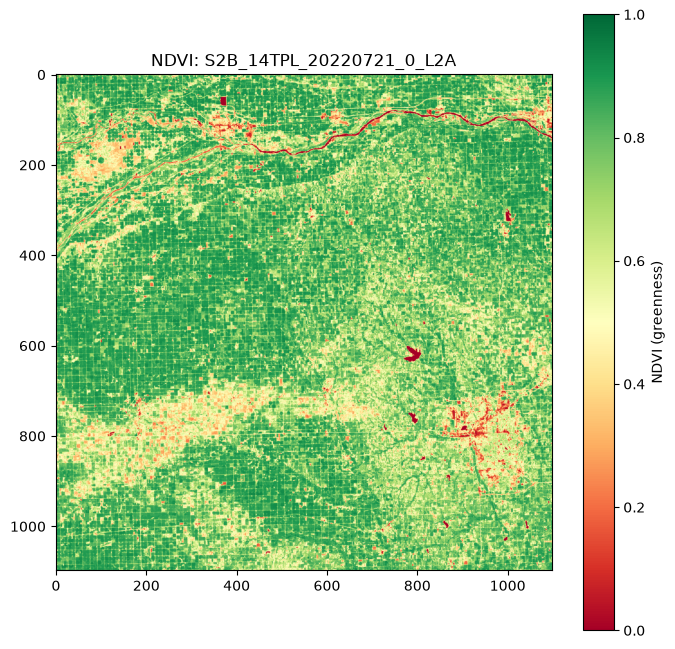

In [9]:
import numpy as np
import matplotlib.pyplot as plt

def read_reflectance(item, band_name, size=1098):
    """Read one colour band as real reflectance values (smaller preview size)."""
    asset = item.assets[band_name]
    label = asset.extra_fields["raster:bands"][0]       # the scale/offset label

    with rasterio.open(asset.href) as src:
        stored = src.read(1, out_shape=(size, size))    # read the smaller version
    stored = stored.astype("float32")                   # allow decimals

    stored[stored == label["nodata"]] = np.nan          # 0 means "no data", so mark blank
        # Earth Search has already removed the offset when this flag is True,
    # so applying it again would subtract it twice.
    if item.properties.get("earthsearch:boa_offset_applied"):
        offset = 0.0
    else:
        offset = label["offset"]
    return stored * label["scale"] + offset

red_r = read_reflectance(item, "red")
nir_r = read_reflectance(item, "nir")

ndvi = (nir_r - red_r) / (nir_r + red_r)

print("NDVI lowest / middle / highest:",
      round(float(np.nanmin(ndvi)), 2),
      round(float(np.nanmedian(ndvi)), 2),
      round(float(np.nanmax(ndvi)), 2))

plt.figure(figsize=(8, 8))
plt.imshow(ndvi, cmap="RdYlGn", vmin=0, vmax=1)
plt.colorbar(label="NDVI (greenness)")
plt.title(f"NDVI: {item.id}")
plt.show()

In [10]:
print(item.assets["red"].href)

https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/14/T/PL/2022/7/S2B_14TPL_20220721_0_L2A/B04.tif
